<a href="https://colab.research.google.com/github/Veniveni123/CSA47-DEEP-LEARNING/blob/main/LAB%2021-30/Experiment%2025%3A%20Restricted%20Boltzmann%20Machine%20Energy%20and%20Reconstruction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Sample Joint Energy E(v, h): -2.283


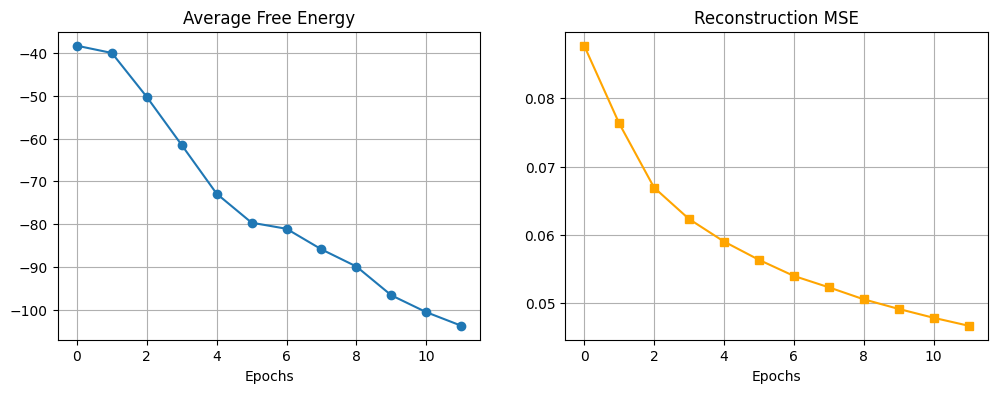

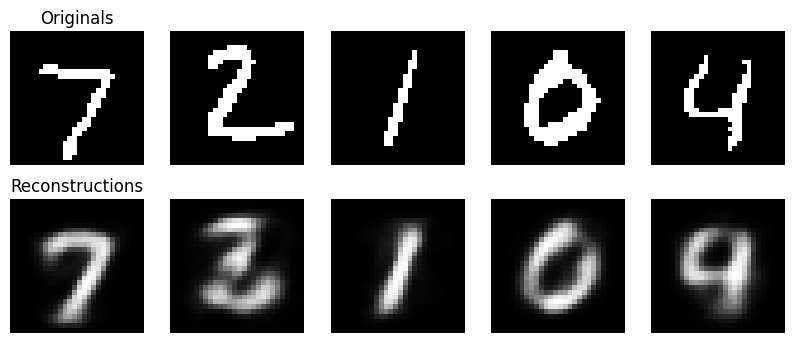

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras

np.random.seed(42)

(X_tr, _), (X_te, _) = keras.datasets.mnist.load_data()
X_train = (X_tr[:3000].reshape(-1, 784) > 127).astype(np.float32)
X_test = (X_te[:100].reshape(-1, 784) > 127).astype(np.float32)

class RBM:
    def __init__(self, n_vis=784, n_hid=64):
        self.W = np.random.normal(0, 0.01, (n_vis, n_hid))
        self.a = np.zeros(n_vis)
        self.b = np.zeros(n_hid)

    def sigmoid(self, x):
        return 1.0 / (1.0 + np.exp(-np.clip(x, -20, 20)))

    def propup(self, v):
        return self.sigmoid(v @ self.W + self.b)

    def propdown(self, h):
        return self.sigmoid(h @ self.W.T + self.a)

    def free_energy(self, v):
        vbias = v @ self.a
        wx_b = v @ self.W + self.b
        hidden_term = np.sum(np.log1p(np.exp(np.clip(wx_b, -20, 20))), axis=1)
        return np.mean(-vbias - hidden_term)

    def joint_energy(self, v, h):
        return -np.dot(v, self.a) - np.dot(h, self.b) - (v @ self.W @ h)

    def train(self, data, lr=0.05, epochs=12, batch_size=64):
        fe_hist, err_hist = [], []
        for _ in range(epochs):
            perm = np.random.permutation(len(data))
            for i in range(0, len(data), batch_size):
                v0 = data[perm[i:i+batch_size]]
                ph0 = self.propup(v0)
                h0 = (np.random.rand(*ph0.shape) < ph0).astype(np.float32)
                pv1 = self.propdown(h0)
                ph1 = self.propup(pv1)

                self.W += lr * ((v0.T @ ph0) - (pv1.T @ ph1)) / len(v0)
                self.a += lr * np.mean(v0 - pv1, axis=0)
                self.b += lr * np.mean(ph0 - ph1, axis=0)

            recon = self.propdown(self.propup(data[:500]))
            err_hist.append(np.mean((data[:500] - recon) ** 2))
            fe_hist.append(self.free_energy(data[:500]))
        return fe_hist, err_hist

rbm = RBM(784, 64)
h_sample = (rbm.propup(X_test[:1])[0] > 0.5).astype(np.float32)
print("Sample Joint Energy E(v, h):", round(rbm.joint_energy(X_test[0], h_sample), 3))

fe_hist, err_hist = rbm.train(X_train)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(fe_hist, 'o-')
axes[0].set_title("Average Free Energy")
axes[0].set_xlabel("Epochs")
axes[0].grid(True)

axes[1].plot(err_hist, 's-', color='orange')
axes[1].set_title("Reconstruction MSE")
axes[1].set_xlabel("Epochs")
axes[1].grid(True)
plt.show()

recons = rbm.propdown(rbm.propup(X_test[:5]))
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i in range(5):
    axes[0, i].imshow(X_test[i].reshape(28, 28), cmap='gray')
    axes[0, i].axis('off')
    axes[1, i].imshow(recons[i].reshape(28, 28), cmap='gray')
    axes[1, i].axis('off')
axes[0, 0].set_title("Originals")
axes[1, 0].set_title("Reconstructions")
plt.show()